# Step 5: Train and evaluate the models

Inputs: `data/train.csv`, `data/val.csv`, `data/test.csv` from step 4.
Output: `data/results.csv`.

Three models (Logistic Regression, Random Forest, XGBoost) on three feature sets
(numerical-only, sentiment-only, multimodal) gives 9 results.
Run the cells one by one. Cell 5.4 is the slow one, a few minutes at most.

## 5.1 Load the splits

In [2]:
%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 5.7 MB/s  0:00:10m0:00:0100:01
Note: you may need to restart the kernel to use updated packages.


In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

train = pd.read_csv("data/train.csv", parse_dates=["Date"])
val = pd.read_csv("data/val.csv", parse_dates=["Date"])
test = pd.read_csv("data/test.csv", parse_dates=["Date"])

for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:10s} {len(part):5d} rows  {part['Date'].min().date()} to {part['Date'].max().date()}")

train       1384 rows  2008-08-22 to 2014-02-21
validation   297 rows  2014-02-24 to 2015-04-28
test         297 rows  2015-04-29 to 2016-06-30


## 5.2 Feature sets, models and tuning grids

Each model has a small grid of settings to try. The grids are kept small on purpose, to limit overfitting on noisy data.

In [4]:
TECH_COLS = ["ret_1d", "ret_5d", "rsi_14", "macd", "macd_signal", "macd_hist", "vol_chg"]
SENT_COLS = ["sent_pos", "sent_neg", "sent_neu"]
FEATURE_SETS = {
    "numerical-only": TECH_COLS,
    "sentiment-only": SENT_COLS,
    "multimodal": TECH_COLS + SENT_COLS,
}

MODELS = {
    "Logistic Regression": (LogisticRegression(max_iter=1000),
                            {"C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                      {"n_estimators": [200], "max_depth": [3, 5, 8], "min_samples_leaf": [5, 20]}),
    "XGBoost": (XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
                {"n_estimators": [100, 300], "max_depth": [2, 3, 4], "learning_rate": [0.03, 0.1]}),
}
y_train, y_val, y_test = train["target"].values, val["target"].values, test["target"].values
print("models:", list(MODELS), "| feature sets:", list(FEATURE_SETS))

models: ['Logistic Regression', 'Random Forest', 'XGBoost'] | feature sets: ['numerical-only', 'sentiment-only', 'multimodal']


## 5.3 Baseline to beat

Always predicting the most common training class.

In [5]:
majority = int(y_train.mean() >= 0.5)
baseline_acc = float((y_test == majority).mean())
print("always predict", "Up" if majority else "Down", "-> test accuracy", round(baseline_acc, 3))

always predict Up -> test accuracy 0.502


## 5.4 Train all 9 combinations

For each feature set:
1. Fit the scaler on the **training** rows only.
2. For each model, tune settings with walk-forward cross-validation (`TimeSeriesSplit`) on the training rows, scored by ROC-AUC.
3. Score the validation set and the test set with the best settings. The test set is not used for any choice.

In [6]:
results, confusions, roc_data, fitted = [], {}, {}, {}

for fs_name, cols in FEATURE_SETS.items():
    scaler = StandardScaler().fit(train[cols])
    X_tr, X_val, X_te = (scaler.transform(p[cols]) for p in (train, val, test))

    for m_name, (est, grid) in MODELS.items():
        gs = GridSearchCV(est, grid, cv=TimeSeriesSplit(n_splits=3), scoring="roc_auc", n_jobs=-1)
        gs.fit(X_tr, y_train)
        best = gs.best_estimator_

        proba = best.predict_proba(X_te)[:, 1]
        pred = (proba >= 0.5).astype(int)

        results.append({
            "feature_set": fs_name, "model": m_name,
            "cv_auc": gs.best_score_,
            "val_auc": roc_auc_score(y_val, best.predict_proba(X_val)[:, 1]),
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred, zero_division=0),
            "f1": f1_score(y_test, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_test, proba),
            "best_params": gs.best_params_,
        })
        confusions[(fs_name, m_name)] = confusion_matrix(y_test, pred, labels=[0, 1])
        roc_data[(fs_name, m_name)] = roc_curve(y_test, proba)[:2]
        fitted[(fs_name, m_name)] = best
        print(f"done: {fs_name:15s} {m_name}")

done: numerical-only  Logistic Regression
done: numerical-only  Random Forest
done: numerical-only  XGBoost
done: sentiment-only  Logistic Regression
done: sentiment-only  Random Forest
done: sentiment-only  XGBoost
done: multimodal      Logistic Regression
done: multimodal      Random Forest
done: multimodal      XGBoost


## 5.5 Results table

All metrics are on the test set, except `cv_auc` (training cross-validation) and `val_auc` (validation set).

In [7]:
res = pd.DataFrame(results)
metric_cols = ["cv_auc", "val_auc", "accuracy", "precision", "recall", "f1", "roc_auc"]
table = res[["feature_set", "model"] + metric_cols].copy()
table[metric_cols] = table[metric_cols].round(3)
table

,feature_set,model,cv_auc,val_auc,accuracy,precision,recall,f1,roc_auc
0,numerical-only,Logistic Regression,0.502,0.580,0.498,0.500,0.993,0.665,0.520
1,numerical-only,Random Forest,0.468,0.517,0.512,0.507,0.913,0.652,0.487
2,numerical-only,XGBoost,0.486,0.475,0.498,0.500,0.926,0.649,0.482
3,sentiment-only,Logistic Regression,0.497,0.484,0.505,0.503,0.973,0.664,0.524
4,sentiment-only,Random Forest,0.515,0.457,0.502,0.502,0.779,0.611,0.520
5,sentiment-only,XGBoost,0.504,0.455,0.478,0.482,0.550,0.514,0.500
6,multimodal,Logistic Regression,0.500,0.538,0.498,0.500,0.933,0.651,0.539
7,multimodal,Random Forest,0.492,0.501,0.512,0.507,0.966,0.665,0.483
8,multimodal,XGBoost,0.505,0.459,0.522,0.515,0.826,0.634,0.481


## 5.6 How much can the accuracy be trusted?

With only a few hundred test days, accuracy has a wide margin of error. A difference smaller than this margin is not a real difference.

In [8]:
n_test = len(y_test)
p = res["accuracy"].mean()
margin = 1.96 * np.sqrt(p * (1 - p) / n_test)
print(f"test days: {n_test}")
print(f"95% margin of error on accuracy: about +/- {margin:.3f} ({margin*100:.1f} percentage points)")
print(f"majority-class baseline: {baseline_acc:.3f}")

test days: 297
95% margin of error on accuracy: about +/- 0.057 (5.7 percentage points)
majority-class baseline: 0.502


## 5.7 Accuracy and ROC-AUC by feature set

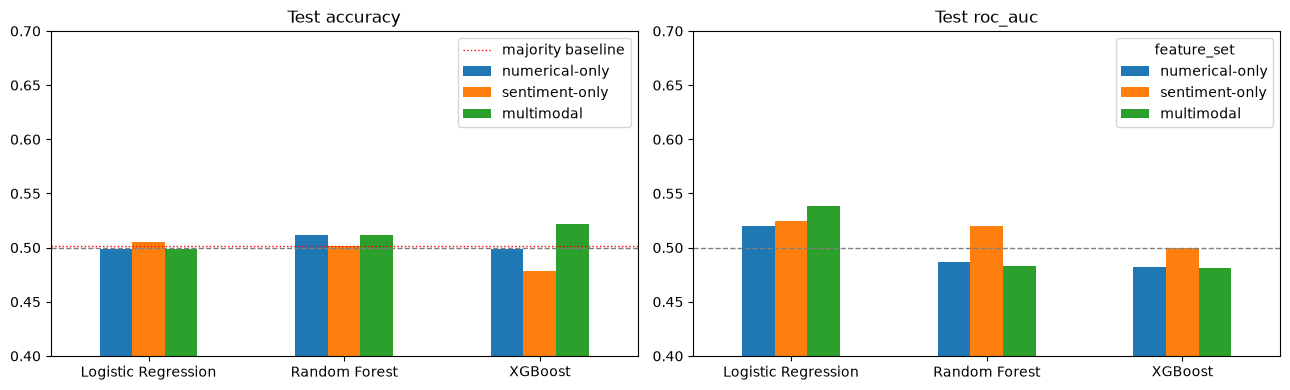

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["accuracy", "roc_auc"]):
    pivot = res.pivot(index="model", columns="feature_set", values=metric)[list(FEATURE_SETS)]
    pivot.plot.bar(ax=ax, rot=0)
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    if metric == "accuracy":
        ax.axhline(baseline_acc, color="red", linestyle=":", linewidth=1, label="majority baseline")
        ax.legend()
    ax.set_title(f"Test {metric}")
    ax.set_xlabel("")
    ax.set_ylim(0.4, max(0.7, pivot.values.max() + 0.05))
plt.tight_layout()
plt.show()

## 5.8 Confusion matrices

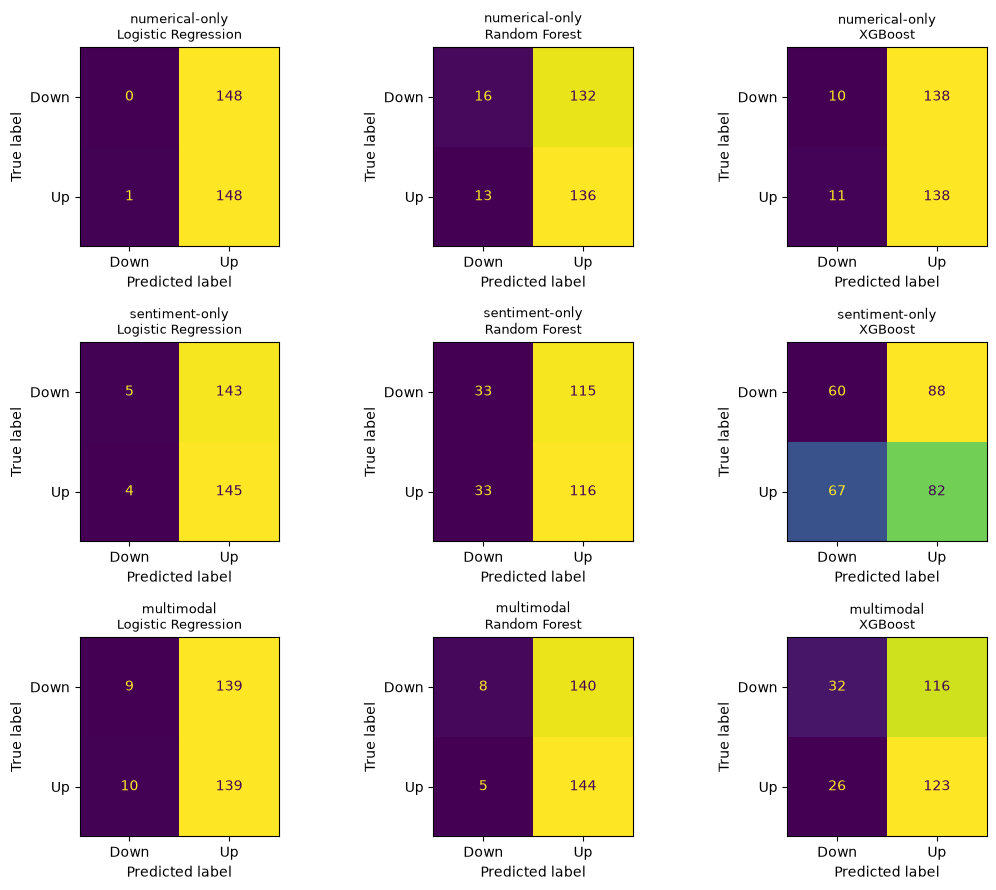

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(11, 9))
for r, fs_name in enumerate(FEATURE_SETS):
    for c, m_name in enumerate(MODELS):
        ConfusionMatrixDisplay(confusions[(fs_name, m_name)], display_labels=["Down", "Up"]).plot(
            ax=axes[r, c], colorbar=False)
        axes[r, c].set_title(f"{fs_name}\n{m_name}", fontsize=9)
plt.tight_layout()
plt.show()

## 5.9 ROC curves

The diagonal is random guessing. A curve hugging the diagonal means little predictive power.

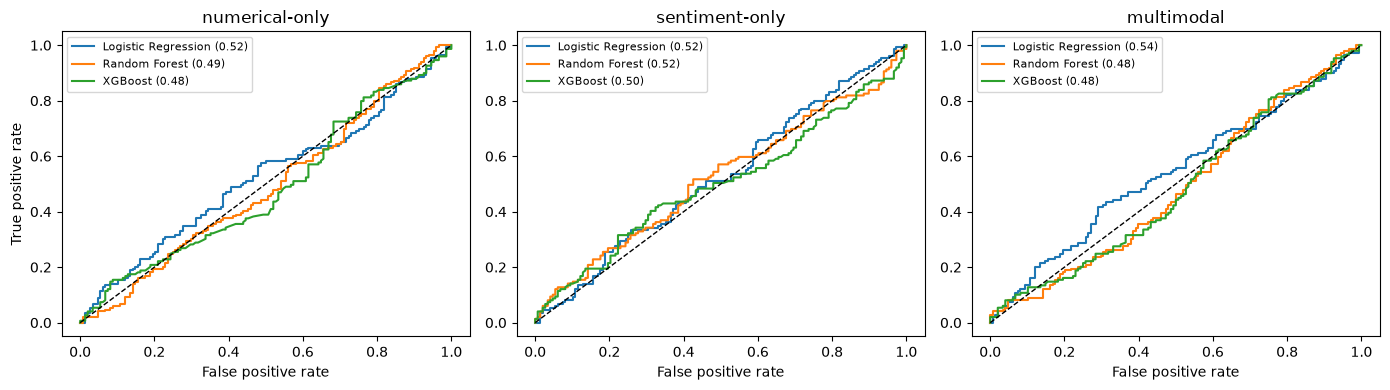

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, fs_name in zip(axes, FEATURE_SETS):
    for m_name in MODELS:
        fpr, tpr = roc_data[(fs_name, m_name)]
        auc = res[(res.feature_set == fs_name) & (res.model == m_name)]["roc_auc"].iloc[0]
        ax.plot(fpr, tpr, label=f"{m_name} ({auc:.2f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_title(fs_name)
    ax.set_xlabel("False positive rate")
    ax.legend(fontsize=8)
axes[0].set_ylabel("True positive rate")
plt.tight_layout()
plt.show()

## 5.10 Which features matter (multimodal models)

Logistic Regression: size of the coefficient on scaled features. Random Forest and XGBoost: feature importance.
This is the interpretability part of the project. Do not read too much into it if the models score near 50 percent.

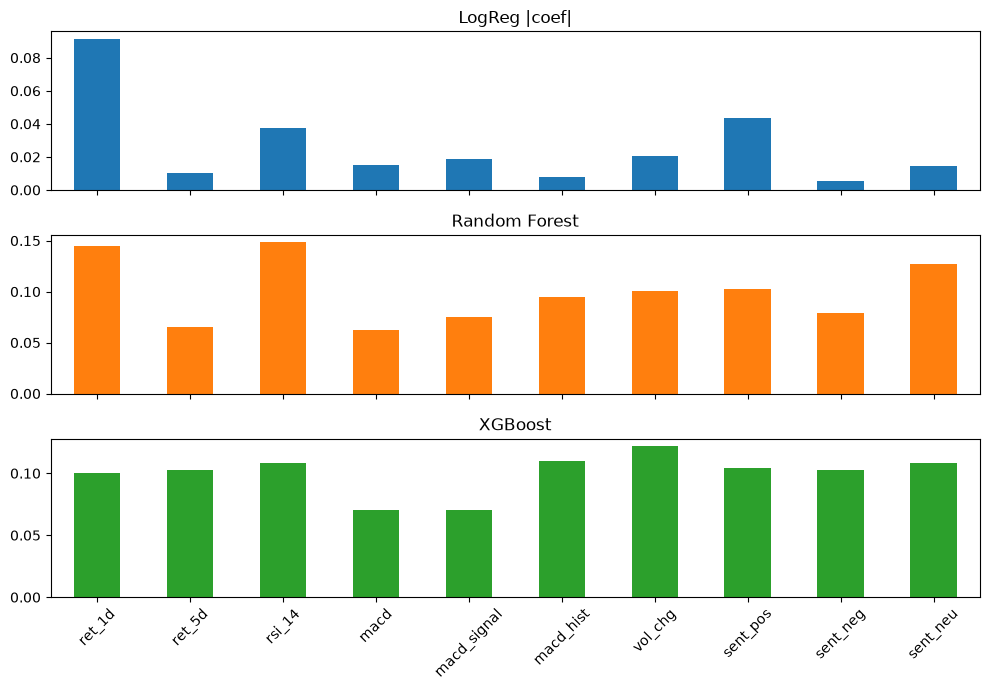

,LogReg |coef|,Random Forest,XGBoost
ret_1d,0.091,0.145,0.100
ret_5d,0.010,0.065,0.103
rsi_14,0.038,0.148,0.108
macd,0.015,0.062,0.070
macd_signal,0.018,0.076,0.071
macd_hist,0.008,0.094,0.110
vol_chg,0.021,0.101,0.122
sent_pos,0.043,0.102,0.104
sent_neg,0.005,0.079,0.103
sent_neu,0.015,0.127,0.109


In [12]:
cols = FEATURE_SETS["multimodal"]
imp = pd.DataFrame(index=cols)
imp["LogReg |coef|"] = np.abs(fitted[("multimodal", "Logistic Regression")].coef_[0])
imp["Random Forest"] = fitted[("multimodal", "Random Forest")].feature_importances_
imp["XGBoost"] = fitted[("multimodal", "XGBoost")].feature_importances_

imp.plot.bar(subplots=True, figsize=(10, 7), legend=False, rot=45)
plt.tight_layout()
plt.show()
imp.round(3)

## 5.11 The main question: does sentiment add value?

Compares the best multimodal model with the best numerical-only model, and also shows each model's change when sentiment is added.

In [13]:
best = res.loc[res.groupby("feature_set")["roc_auc"].idxmax(), ["feature_set", "model", "accuracy", "roc_auc"]]
print(best.round(3).to_string(index=False))

num = res[res.feature_set == "numerical-only"].set_index("model")
mm = res[res.feature_set == "multimodal"].set_index("model")
delta = pd.DataFrame({"accuracy change": mm["accuracy"] - num["accuracy"],
                      "roc_auc change": mm["roc_auc"] - num["roc_auc"]}).round(3)
print("\nmultimodal minus numerical-only, per model:")
print(delta.to_string())

print(f"\nBest multimodal ROC-AUC minus best numerical-only ROC-AUC: "
      f"{mm['roc_auc'].max() - num['roc_auc'].max():+.3f}")
print(f"For scale, the accuracy margin of error is about +/- {margin:.3f}.")

   feature_set               model  accuracy  roc_auc
    multimodal Logistic Regression     0.498    0.539
numerical-only Logistic Regression     0.498    0.520
sentiment-only Logistic Regression     0.505    0.524

multimodal minus numerical-only, per model:
                     accuracy change  roc_auc change
model                                               
Logistic Regression            0.000           0.019
Random Forest                  0.000          -0.004
XGBoost                        0.024          -0.001

Best multimodal ROC-AUC minus best numerical-only ROC-AUC: +0.019
For scale, the accuracy margin of error is about +/- 0.057.


## 5.12 Save

In [ ]:
res.to_csv("data/results.csv", index=False)
print("saved data/results.csv with", len(res), "rows")

saved data/results.csv with 9 rows


## How to write up the results

- Compare accuracy with the majority-class baseline, not with 100 percent. Next-day direction is close to a coin flip, so 50 to 55 percent is normal.
- If multimodal does not clearly beat numerical-only, say so. That is a valid finding: in this data, headline sentiment added little beyond price indicators.
- Differences smaller than the margin of error in 5.6 are not evidence either way.
- Limits to state: the test period is one stretch of about a year; the Kaggle headlines are general world news, not financial news; the dataset ends in 2016.